# Evaluación Parcial N°5 — CASO 2: Salud: Costos Médicos y Bienestar del Paciente

**Asignatura:** SCY1102 — Gestión de Proyectos de Datos · **Integrantes:** Nicolás Fonseca Olivares, Cristobal Segovia Retamal, Bastian Rubio Meneses

**Caso:** una aseguradora de salud privada quiere entender qué características de sus afiliados (edad, IMC, tabaquismo, número de hijos, región) se asocian a un mayor riesgo financiero, para estimar presupuestos, mejorar la planificación y ofrecer programas preventivos más efectivos.

Este notebook es la **implementación técnica** del proyecto planificado en el informe de factibilidad (EP2): EDA, ingeniería de variables, modelado con validación cruzada, evaluación, explicabilidad (SHAP) y auditoría de equidad. Las secciones 1.1 a 1.3 (ética, finanzas y riesgos) se mantienen del informe EP2.

**Estructura:**

1. Evidencia de los datos y EDA
2. Ingeniería de variables
3. Modelado y comparación de algoritmos (métricas en USD)
4. Evaluación, residuos, importancia de variables y SHAP
5. Verificación de criterios de aceptación del informe (RF02)
6. 1.1 Análisis ético (con auditoría de equidad sobre el modelo final) · 1.2 Evaluación financiera · 1.3 Análisis de riesgos · Conclusión · Referencias

> Requiere `insurance.csv` en el mismo directorio y las librerías de la celda siguiente (`shap` se instala con `pip install shap`). Ejecutar con *Restart & Run All*.


In [1]:
# pip install -r requirements.txt

In [2]:
# Versiones de librerías (reproducibilidad)
import platform
import pandas as pd, numpy as np, matplotlib, seaborn as sns, scipy, sklearn
print('Python', platform.python_version())
for lib in [pd, np, matplotlib, sns, scipy, sklearn]:
    print(f'{lib.__name__:<12} {lib.__version__}')
try:
    import shap
    print(f'{"shap":<12} {shap.__version__}')
except ImportError:
    print('shap no instalado → ejecutar: pip install shap')


Python 3.14.5
pandas       3.0.3
numpy        2.4.6
matplotlib   3.10.9
seaborn      0.13.2
scipy        1.17.1
sklearn      1.9.0


c:\Users\Bastian\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap         0.54.1


## Evidencia de los datos

Se verifica la calidad del dataset y se extraen los hechos que sustentan el análisis ético y financiero del caso.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

# Etiquetas y colores comunes para todos los gráficos
etiq_fum = {'no': 'No fumador', 'yes': 'Fumador'}
paleta_fum = {'No fumador': '#4C72B0', 'Fumador': '#C44E52'}

# Carga y limpieza
raw = pd.read_csv('insurance.csv')
df = raw.drop_duplicates().reset_index(drop=True)
df['obese_smoker'] = ((df['bmi'] >= 30) & (df['smoker'] == 'yes')).astype(int)

# Estadísticas
print('Registros originales:', raw.shape[0], '| Duplicados eliminados:', raw.shape[0] - df.shape[0])
print('Registros (sin duplicados):', df.shape[0], '| Nulos:', df.isna().sum().sum())
print('Región:', df['region'].value_counts().to_dict())
print('Sexo:', df['sex'].value_counts().to_dict())
print('Edad: {}-{} años (media {:.1f})'.format(df['age'].min(), df['age'].max(), df['age'].mean()))
print('Fumadores: {} ({:.1f}% de la cartera)'.format((df['smoker'] == 'yes').sum(), (df['smoker'] == 'yes').mean() * 100))
print('Costo medio fumadores: ${:,.0f} | No fumadores: ${:,.0f} (factor {:.1f}x)'.format(
    df.loc[df['smoker'] == 'yes', 'charges'].mean(),
    df.loc[df['smoker'] == 'no', 'charges'].mean(),
    df.loc[df['smoker'] == 'yes', 'charges'].mean() / df.loc[df['smoker'] == 'no', 'charges'].mean()))


Registros originales: 1338 | Duplicados eliminados: 1
Registros (sin duplicados): 1337 | Nulos: 0
Región: {'southeast': 364, 'southwest': 325, 'northwest': 324, 'northeast': 324}
Sexo: {'male': 675, 'female': 662}
Edad: 18-64 años (media 39.2)
Fumadores: 274 (20.5% de la cartera)
Costo medio fumadores: $32,050 | No fumadores: $8,441 (factor 3.8x)


          age     bmi  children  charges
count  1337.0  1337.0    1337.0   1337.0
mean     39.2    30.7       1.1  13279.1
std      14.0     6.1       1.2  12110.4
min      18.0    16.0       0.0   1121.9
25%      27.0    26.3       0.0   4746.3
50%      39.0    30.4       1.0   9386.2
75%      51.0    34.7       2.0  16657.7
max      64.0    53.1       5.0  63770.4

Asimetría de charges: 1.52 | Media $13,279 vs mediana $9,386


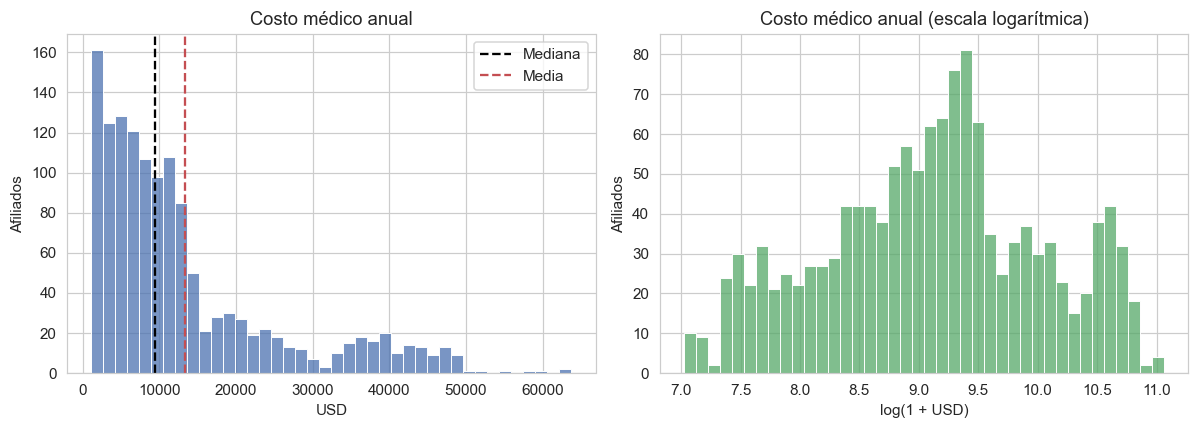

In [4]:
# Distribución de la variable objetivo (costo anual)
print(df[['age', 'bmi', 'children', 'charges']].describe().round(1).to_string())
print('\nAsimetría de charges: {:.2f} | Media ${:,.0f} vs mediana ${:,.0f}'.format(
    df['charges'].skew(), df['charges'].mean(), df['charges'].median()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['charges'], bins=40, ax=axes[0], color='#4C72B0')
axes[0].axvline(df['charges'].median(), color='k', ls='--', label='Mediana')
axes[0].axvline(df['charges'].mean(), color='#C44E52', ls='--', label='Media')
axes[0].set_title('Costo médico anual')
axes[0].set_xlabel('USD')
axes[0].set_ylabel('Afiliados')
axes[0].legend()
sns.histplot(np.log1p(df['charges']), bins=40, ax=axes[1], color='#55A868')
axes[1].set_title('Costo médico anual (escala logarítmica)')
axes[1].set_xlabel('log(1 + USD)')
axes[1].set_ylabel('Afiliados')
plt.tight_layout()
plt.show()

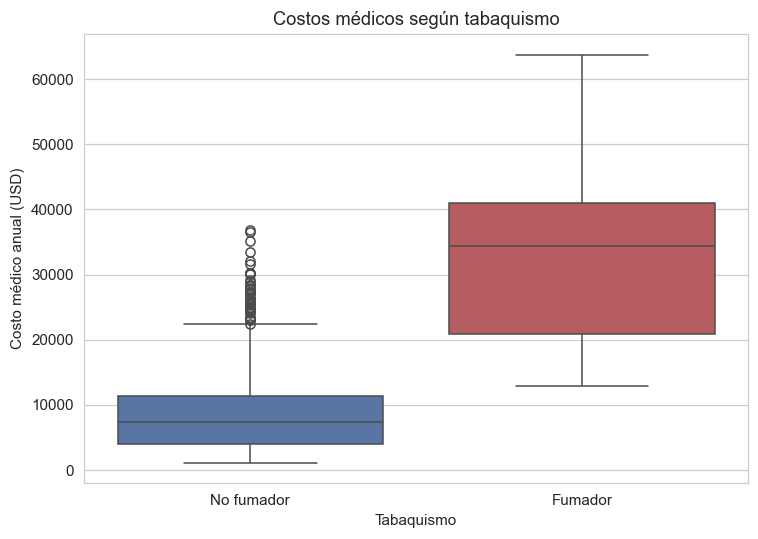

In [5]:
plot_df = df.assign(Tabaquismo=df['smoker'].map(etiq_fum))
plt.figure(figsize=(7, 5))
sns.boxplot(data=plot_df, x='Tabaquismo', y='charges', hue='Tabaquismo', order=['No fumador', 'Fumador'],
            hue_order=['No fumador', 'Fumador'], palette=paleta_fum, legend=False)
plt.xlabel('Tabaquismo')
plt.ylabel('Costo médico anual (USD)')
plt.title('Costos médicos según tabaquismo')
plt.tight_layout()
plt.show()

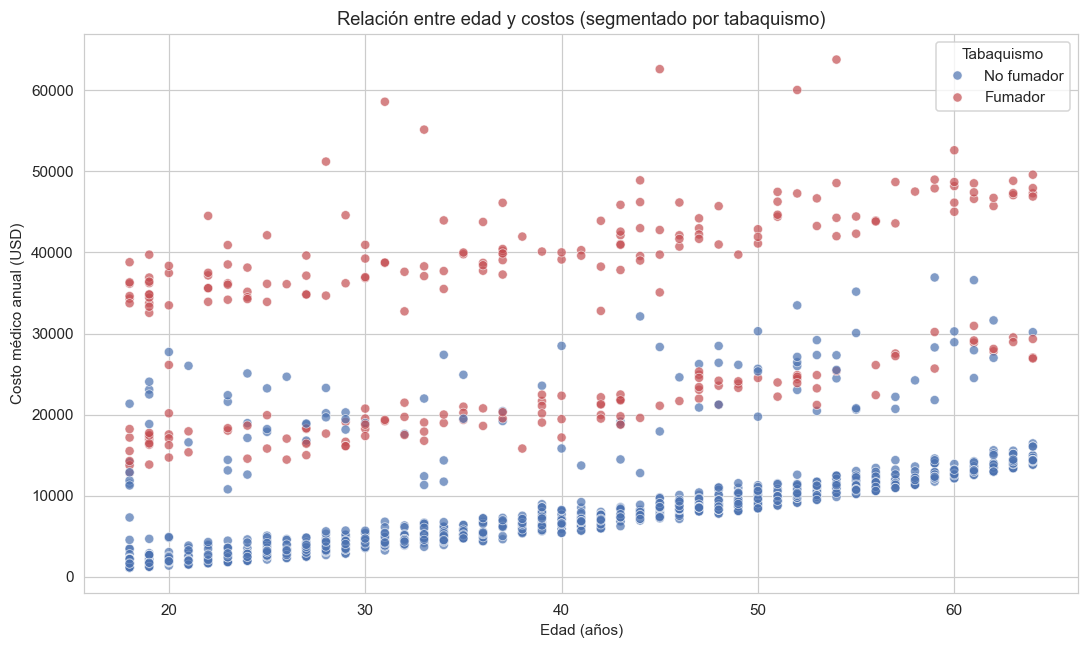

In [6]:
# Relación entre edad, costos y tabaquismo
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x='age', y='charges', hue='Tabaquismo', hue_order=['No fumador', 'Fumador'],
                alpha=0.7, palette=paleta_fum)
plt.title('Relación entre edad y costos (segmentado por tabaquismo)')
plt.xlabel('Edad (años)')
plt.ylabel('Costo médico anual (USD)')
plt.tight_layout()
plt.show()

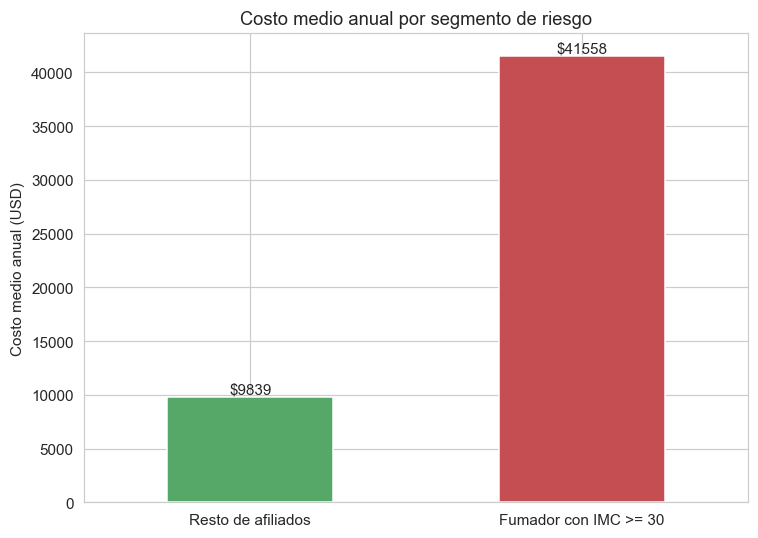

,mean,count,sum,% de la cartera
Resto de afiliados,9839.2,1192,11728276.9,89.2
Fumador con IMC >= 30,41558.0,145,6025908.5,10.8


Factor segmento / resto: 4.2x


In [7]:
# Cálculo de la segmentación
seg = df.groupby('obese_smoker')['charges'].agg(['mean', 'count', 'sum'])
seg.index = ['Resto de afiliados', 'Fumador con IMC >= 30']
seg['% de la cartera'] = seg['count'] / len(df) * 100

# Visualización
fig, ax = plt.subplots(figsize=(7, 5))
seg['mean'].plot(kind='bar', ax=ax, color=['#55A868', '#C44E52'], rot=0)
ax.set_title('Costo medio anual por segmento de riesgo')
ax.set_ylabel('Costo medio anual (USD)')
ax.bar_label(ax.containers[0], fmt='$%.0f')
plt.tight_layout()
plt.show()

# Mostrar la tabla resumen
display(seg.round(1))
print('Factor segmento / resto: {:.1f}x'.format(seg.loc['Fumador con IMC >= 30', 'mean'] / seg.loc['Resto de afiliados', 'mean']))

In [8]:
# Composición y costo por región y sexo (revisión de representatividad)
def resumen_grupo(col):
    return df.groupby(col).agg(afiliados=('charges', 'size'),
                               pct_fumadores=('smoker', lambda s: (s == 'yes').mean() * 100),
                               costo_medio=('charges', 'mean'),
                               costo_mediano=('charges', 'median')).round(1)

display(resumen_grupo('region'))
display(resumen_grupo('sex'))

,afiliados,pct_fumadores,costo_medio,costo_mediano
region,,,,
northeast,324,20.7,13406.4,10057.7
northwest,324,17.9,12450.8,8977.0
southeast,364,25.0,14735.4,9294.1
southwest,325,17.8,12346.9,8798.6


,afiliados,pct_fumadores,costo_medio,costo_mediano
sex,,,,
female,662,17.4,12569.6,9413.0
male,675,23.6,13975.0,9377.9


## EDA Profundo: Relaciones entre variables

**¿Qué hacemos?** Analizar cómo se relacionan las variables entre sí y con el costo médico.

**¿Por qué?** La aseguradora necesita saber qué factores se asocian a mayor costo.
Una matriz de correlación y distribuciones por categoría nos muestran patrones
que un solo gráfico no revela.

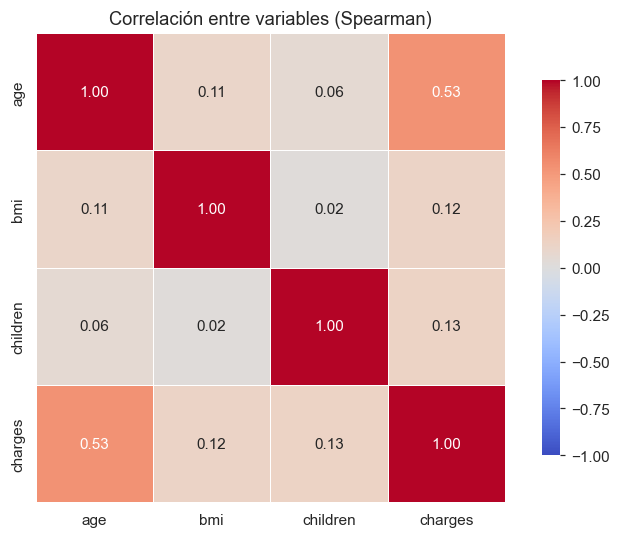


📌 Interpretación:
   • age ↔ charges: 0.53 (correlación moderada)
   • bmi ↔ charges: 0.12 (correlación baja en general)
   • bmi ↔ age:     0.11 (casi independientes)
   • children ↔ charges: 0.13 (baja)

   ⚠️ La correlación bmi↔charges parece baja porque el efecto del IMC
   depende de si la persona fuma o no (interacción). Lo vemos abajo.


In [9]:
# ============================================================
# PASO 1.1 – Matriz de correlación
# ============================================================
# ¿Qué hace este código?
# Calcula la correlación de Spearman entre todas las variables numéricas.
# Spearman se usa porque "charges" tiene asimetría (no es distribución normal).
# El heatmap nos muestra visualmente qué variables suben o bajan juntas.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Seleccionamos solo columnas numéricas para la correlación
cols_numericas = ['age', 'bmi', 'children', 'charges']

# Calculamos correlación de Spearman (funciona bien con datos asimétricos)
matriz_corr = df[cols_numericas].corr(method='spearman')

# Graficamos el heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlación entre variables (Spearman)')
plt.tight_layout()
plt.show()

# Interpretación rápida en texto
print("\n📌 Interpretación:")
print(f"   • age ↔ charges: {matriz_corr.loc['age','charges']:.2f} (correlación moderada)")
print(f"   • bmi ↔ charges: {matriz_corr.loc['bmi','charges']:.2f} (correlación baja en general)")
print(f"   • bmi ↔ age:     {matriz_corr.loc['bmi','age']:.2f} (casi independientes)")
print(f"   • children ↔ charges: {matriz_corr.loc['children','charges']:.2f} (baja)")
print("\n   ⚠️ La correlación bmi↔charges parece baja porque el efecto del IMC")
print("   depende de si la persona fuma o no (interacción). Lo vemos abajo.")

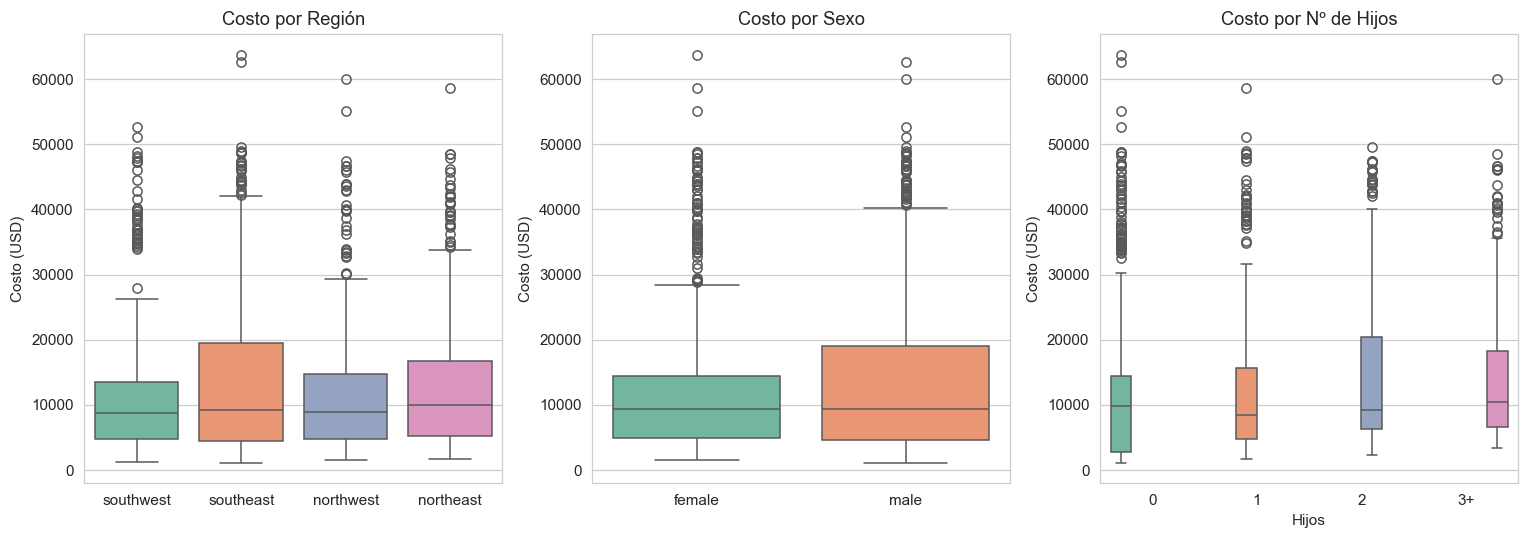


📌 Costo mediano por región:
region
northeast    10058.0
northwest     8977.0
southeast     9294.0
southwest     8799.0

📌 Costo mediano por sexo:
sex
female    9413.0
male      9378.0


In [10]:
# ============================================================
# PASO 1.2 – Distribución de costos por región, sexo y nº de hijos
# ============================================================
# ¿Qué hace este código?
# Crea 3 gráficos de caja (boxplot) para comparar cómo se distribuye
# el costo médico según región, sexo y cantidad de hijos.
# Esto responde: ¿hay diferencias de costo entre grupos demográficos?
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# --- Gráfico 1: Costo por Región ---
# Boxplot para ver si alguna región tiene costos más altos
sns.boxplot(data=df, x='region', y='charges', hue='region', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title('Costo por Región')
axes[0].set_xlabel('')
axes[0].set_ylabel('Costo (USD)')

# --- Gráfico 2: Costo por Sexo ---
sns.boxplot(data=df, x='sex', y='charges', hue='sex', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Costo por Sexo')
axes[1].set_xlabel('')
axes[1].set_ylabel('Costo (USD)')

# --- Gráfico 3: Costo por número de hijos ---
# Agrupamos 4+ hijos en una sola categoría para no tener barras vacías
df_temp = df.copy()
df_temp['children_grp'] = pd.cut(df_temp['children'], bins=[-1, 0, 1, 2, 5],
                                  labels=['0', '1', '2', '3+'])
sns.boxplot(data=df_temp, x='children_grp', y='charges', hue='children_grp', legend=False, ax=axes[2], palette='Set2')
axes[2].set_title('Costo por Nº de Hijos')
axes[2].set_xlabel('Hijos')
axes[2].set_ylabel('Costo (USD)')

plt.tight_layout()
plt.show()

# Resumen numérico rápido
print("\n📌 Costo mediano por región:")
print(df.groupby('region')['charges'].median().round(0).to_string())
print(f"\n📌 Costo mediano por sexo:")
print(df.groupby('sex')['charges'].median().round(0).to_string())

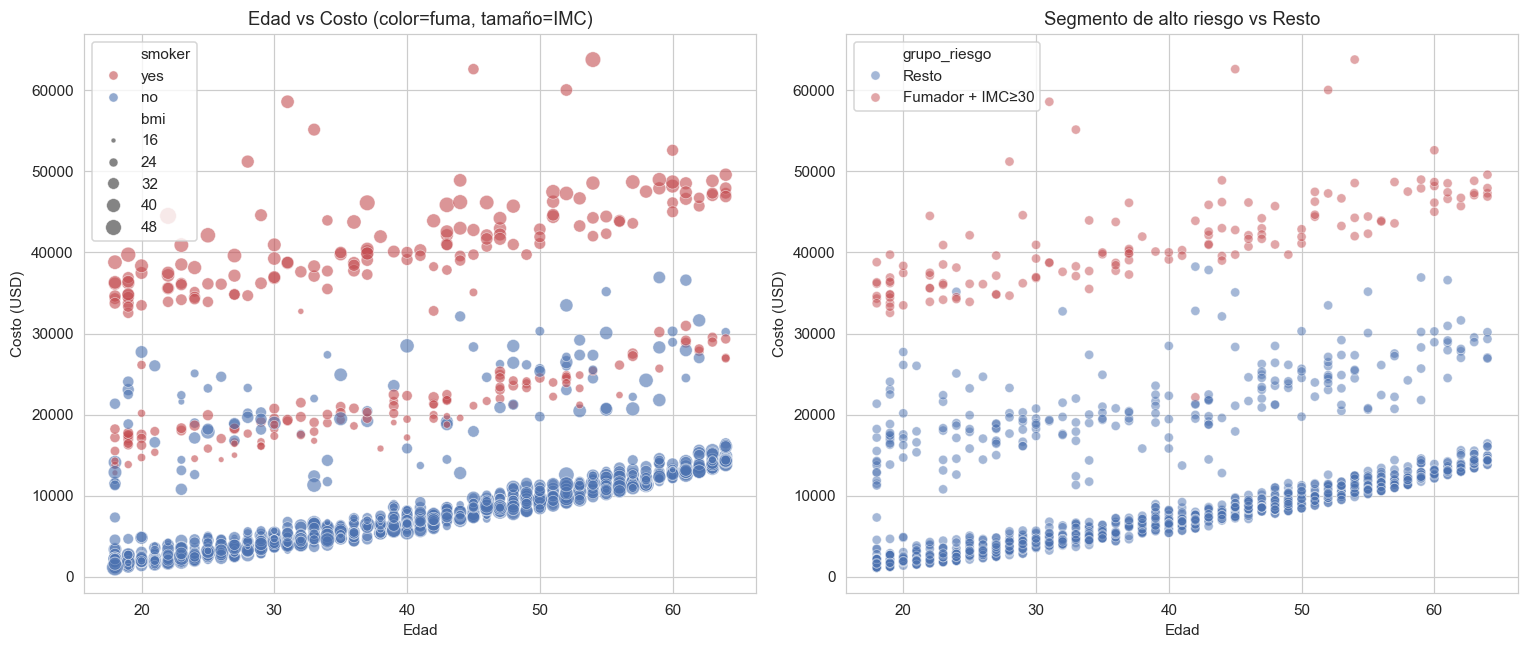


📌 Hallazgo clave:
   El IMC por sí solo se asocia poco al costo (ver correlación).
   Es la COMBINACIÓN tabaquismo + obesidad la que dispara el costo.
   Esto motiva probar la variable 'obese_smoker'; su aporte real al modelo se mide en la ablación (PASO 3.4).


In [11]:
# ============================================================
# PASO 1.3 – Interacción: Edad × IMC × Tabaquismo sobre el costo
# ============================================================
# ¿Qué hace este código?
# Crea un scatter de edad vs costo, coloreado por tabaquismo,
# y con tamaño de punto proporcional al IMC.
# Esto muestra visualmente que el IMC alto solo dispara el costo
# cuando se combina con tabaquismo.
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel izquierdo: todos los puntos
sns.scatterplot(data=df, x='age', y='charges', hue='smoker',
                size='bmi', sizes=(10, 120), alpha=0.6,
                palette={'no': '#4C72B0', 'yes': '#C44E52'}, ax=axes[0])
axes[0].set_title('Edad vs Costo (color=fuma, tamaño=IMC)')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Costo (USD)')

# Panel derecho: solo fumadores con IMC >= 30 vs el resto
# Esto evidencia el segmento de riesgo identificado en el EDA inicial
df['grupo_riesgo'] = np.where(df['obese_smoker'] == 1,
                               'Fumador + IMC≥30', 'Resto')
sns.scatterplot(data=df, x='age', y='charges', hue='grupo_riesgo',
                alpha=0.5, palette={'Resto': '#4C72B0',
                                     'Fumador + IMC≥30': '#C44E52'}, ax=axes[1])
axes[1].set_title('Segmento de alto riesgo vs Resto')
axes[1].set_xlabel('Edad')
axes[1].set_ylabel('Costo (USD)')

plt.tight_layout()
plt.show()

# Justificación
print("\n📌 Hallazgo clave:")
print("   El IMC por sí solo se asocia poco al costo (ver correlación).")
print("   Es la COMBINACIÓN tabaquismo + obesidad la que dispara el costo.")
print("   Esto motiva probar la variable 'obese_smoker'; su aporte real al modelo se mide en la ablación (PASO 3.4).")

## Feature Engineering: Crear variables más informativas

**¿Qué hacemos?** Transformar variables continuas en categorías con sentido médico
y crear variables de interacción.

**¿Por qué?** Un modelo lineal o de árbol trabaja mejor con categorías
clínicas (ej: "Obesidad grado II") que con números crudos (ej: BMI=34.7).
Las interacciones capturan efectos combinados que una sola variable no muestra.

Distribución por categoría de IMC:
bmi_category
Bajo peso        21
Normal          226
Sobrepeso       386
Obesidad I      388
Obesidad II     225
Obesidad III     91


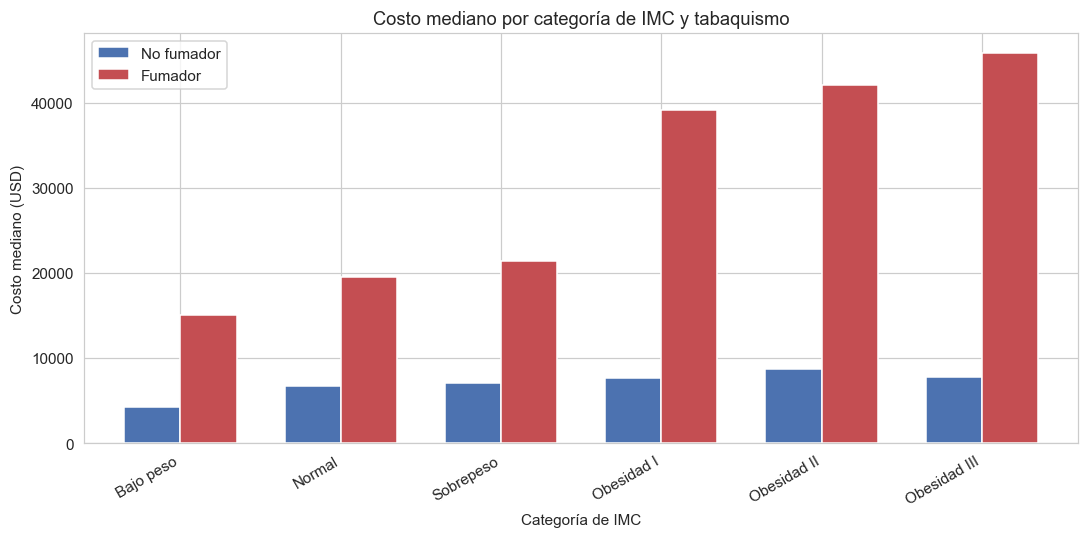


📌 Conclusión:
   En NO fumadores, el IMC casi no afecta el costo.
   En FUMADORES, el costo se dispara a partir de Obesidad I.
   → La interacción bmi×smoker es el predictor clave.


In [12]:
# ============================================================
# PASO 2.1 – Categorización del IMC según OMS
# ============================================================
# ¿Qué hace este código?
# Crea una columna nueva 'bmi_category' que clasifica el IMC
# en categorías médicas estándar de la OMS.
# Esto permite que el modelo y los gráficos hablen en "idioma médico".
# ============================================================

# Definimos los cortes según la clasificación OMS
cortes_bmi = [0, 18.5, 25, 30, 35, 40, 100]
etiquetas_bmi = ['Bajo peso', 'Normal', 'Sobrepeso',
                 'Obesidad I', 'Obesidad II', 'Obesidad III']

# Creamos la nueva columna
df['bmi_category'] = pd.cut(df['bmi'], bins=cortes_bmi, labels=etiquetas_bmi)

# Verificación rápida: contamos cuántas personas hay en cada categoría
print("Distribución por categoría de IMC:")
print(df['bmi_category'].value_counts().sort_index().to_string())

# Gráfico de costo mediano por categoría de IMC, separado por tabaquismo
fig, ax = plt.subplots(figsize=(10, 5))
resumen = df.groupby(['bmi_category', 'smoker'], observed=True)['charges'].median().unstack()
resumen = resumen[['no', 'yes']]  # ordenamos columnas
resumen.columns = ['No fumador', 'Fumador']
resumen.plot(kind='bar', ax=ax, color=['#4C72B0', '#C44E52'], width=0.7)
ax.set_title('Costo mediano por categoría de IMC y tabaquismo')
ax.set_ylabel('Costo mediano (USD)')
ax.set_xlabel('Categoría de IMC')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Justificación
print("\n📌 Conclusión:")
print("   En NO fumadores, el IMC casi no afecta el costo.")
print("   En FUMADORES, el costo se dispara a partir de Obesidad I.")
print("   → La interacción bmi×smoker es el predictor clave.")

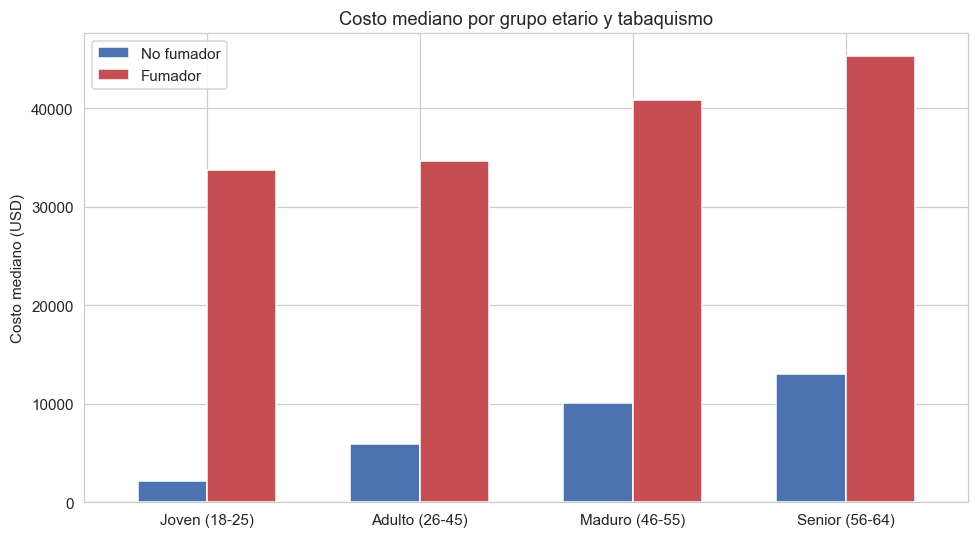

,No fumador,Fumador
age_group,,
Joven (18-25),2209.0,33750.0
Adulto (26-45),5967.0,34672.0
Maduro (46-55),10069.0,40847.0
Senior (56-64),12982.0,45360.0



📌 Conclusión:
   En NO fumadores el costo mediano crece de forma sostenida con la edad.
   En FUMADORES el costo ya es alto desde los 18-25 años y sube de forma más moderada con la edad.


In [13]:
# ============================================================
# PASO 2.2 – Tramos etarios
# ============================================================
# ¿Qué hace este código?
# Agrupa la edad en tramos con sentido para una aseguradora:
#   Jóvenes (18-25), Adultos (26-45), Maduros (46-55), Seniors (56-64)
# Esto facilita el análisis de riesgo por grupo y la comunicación al negocio.
# ============================================================

cortes_edad = [17, 25, 45, 55, 64]
etiquetas_edad = ['Joven (18-25)', 'Adulto (26-45)',
                  'Maduro (46-55)', 'Senior (56-64)']

df['age_group'] = pd.cut(df['age'], bins=cortes_edad, labels=etiquetas_edad)

# Resumen: costo mediano por grupo etario × tabaquismo
resumen_edad = df.groupby(['age_group', 'smoker'], observed=True)['charges'].median().unstack()
resumen_edad.columns = ['No fumador', 'Fumador']

fig, ax = plt.subplots(figsize=(9, 5))
resumen_edad.plot(kind='bar', ax=ax, color=['#4C72B0', '#C44E52'], width=0.65)
ax.set_title('Costo mediano por grupo etario y tabaquismo')
ax.set_ylabel('Costo mediano (USD)')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(resumen_edad.round(0))
print("\n📌 Conclusión:")
print("   En NO fumadores el costo mediano crece de forma sostenida con la edad.")
print("   En FUMADORES el costo ya es alto desde los 18-25 años y sube de forma más moderada con la edad.")


In [14]:
# ============================================================
# PASO 2.3 – Variable de interacción edad × IMC
# ============================================================
# ¿Qué hace este código?
# Crea una variable numérica que multiplica edad × IMC.
# La idea: una persona de 60 años con IMC 40 tiene más riesgo
# que una de 20 años con el mismo IMC.
# La multiplicación captura ese efecto combinado.
# ============================================================

df['age_bmi_interaction'] = df['age'] * df['bmi']

# Verificación: vemos la correlación de la nueva variable con el costo
corr_interaction = df['age_bmi_interaction'].corr(df['charges'], method='spearman')
print(f"Correlación (Spearman) age×bmi ↔ charges: {corr_interaction:.3f}")
print(f"Correlación (Spearman) age    ↔ charges: {df['age'].corr(df['charges'], method='spearman'):.3f}")
print(f"Correlación (Spearman) bmi    ↔ charges: {df['bmi'].corr(df['charges'], method='spearman'):.3f}")
if corr_interaction > max(df['age'].corr(df['charges'], method='spearman'),
                          df['bmi'].corr(df['charges'], method='spearman')):
    print("\n📌 La interacción age×bmi correlaciona más con el costo que cada variable por separado.")
else:
    print("\n📌 La interacción age×bmi NO supera a 'age' por sí sola; se incluye como candidata")
    print("   y su aporte real se evalúa con la ablación de variables (PASO 3.4).")

# Guardamos la lista final de variables que usará el modelo
features_numericas = ['age', 'bmi', 'children', 'obese_smoker', 'age_bmi_interaction']
features_categoricas = ['sex', 'smoker', 'region']
target = 'charges'

print(f"\n✅ Variables predictoras numéricas:     {features_numericas}")
print(f"✅ Variables predictoras categóricas:   {features_categoricas}")
print(f"✅ Variable objetivo:                   {target}")

Correlación (Spearman) age×bmi ↔ charges: 0.501
Correlación (Spearman) age    ↔ charges: 0.534
Correlación (Spearman) bmi    ↔ charges: 0.120

📌 La interacción age×bmi NO supera a 'age' por sí sola; se incluye como candidata
   y su aporte real se evalúa con la ablación de variables (PASO 3.4).

✅ Variables predictoras numéricas:     ['age', 'bmi', 'children', 'obese_smoker', 'age_bmi_interaction']
✅ Variables predictoras categóricas:   ['sex', 'smoker', 'region']
✅ Variable objetivo:                   charges


**Hechos clave para el análisis ético y financiero:**

- **Calidad de datos:** el archivo original tiene 1.338 filas; se elimina 1 duplicado y quedan **1.337 afiliados sin nulos**. Edades de 18 a 64 años (no hay afiliados de 65 o más, por lo que los resultados no se extienden a adultos mayores).
- **Costo anual:** la distribución es asimétrica (media \$13.279 vs mediana \$9.386; asimetría 1,52), con una cola de casos muy costosos. Por eso el prototipo del modelo trabaja con el logaritmo del costo.
- **Tabaquismo:** los fumadores son el **20,5%** de la cartera (274 de 1.337) y su costo medio anual es **\$32.050 vs \$8.441** de los no fumadores (3,8 veces más).
- **Segmento de máximo riesgo:** los **fumadores con IMC ≥ 30** (145 afiliados, 10,8%) cuestan en promedio **\$41.558 anuales, 4,2 veces** el resto (\$9.839), unos **\$6,03 millones al año** en total. Es el candidato natural para programas preventivos.
- **Representatividad: la composición está balanceada, pero eso no basta para descartar sesgos.** Las regiones tienen entre 324 y 364 casos y el sexo se reparte 675/662. Sin embargo, el tabaquismo no se reparte igual: 23,6% en hombres vs 17,4% en mujeres, y 25,0% en la región southeast vs 17,8%–20,7% en las demás. Esto se refleja en el costo medio regional (southeast \$14.735 vs southwest \$12.347). Además, las regiones del archivo son de EE. UU., así que la representatividad frente a la cartera real del cliente debe confirmarse con sus propios datos.

## Modelado: Comparación de algoritmos con validación cruzada

**¿Qué hacemos?** Definir una partición train/test única, un preprocesamiento común y una función de evaluación **en dólares**; luego comparar dos baselines (mediana y regresión lineal) con Random Forest y Gradient Boosting usando validación cruzada de 5 particiones.

**¿Por qué?**
- El modelo se entrena sobre `log1p(charges)` porque el costo es asimétrico, pero **todas las métricas se calculan en USD** (se revierte con `expm1`) para que sean comparables entre modelos y con los criterios de aceptación del informe (R² ≥ 0,85; MAE < $2.100).
- La validación cruzada evita que el resultado dependa de una sola partición favorable.
- El ajuste de hiperparámetros se hace **solo con el conjunto de entrenamiento**; el conjunto de prueba (20%) se usa una única vez para la evaluación final.


In [15]:
# ============================================================
# PASO 3.0 – Partición, preprocesamiento y funciones de evaluación (USD)
# ============================================================
# ¿Qué hace este código?
# 1) Separa 80% entrenamiento / 20% prueba (semilla fija).
# 2) Define el preprocesamiento (one-hot para categóricas).
# 3) Define funciones que evalúan siempre en dólares (no en log).
# ============================================================

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

X = df[features_numericas + features_categoricas]
y = np.log1p(df[target])                      # el modelo aprende en escala log

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_test_real = np.expm1(y_test)                # costo real en USD del conjunto de prueba
print(f"Entrenamiento: {len(X_train)} afiliados | Prueba: {len(X_test)} afiliados")

preprocessor = ColumnTransformer([
    ('num', 'passthrough', features_numericas),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), features_categoricas)
])

def crear_pipeline(regresor):
    return Pipeline([('prep', preprocessor), ('modelo', regresor)])

# Scorers en dólares: reciben el pipeline, X y el objetivo en log
def mae_dolares(est, X_, y_log):
    return -mean_absolute_error(np.expm1(y_log), np.expm1(est.predict(X_)))

def r2_dolares(est, X_, y_log):
    return r2_score(np.expm1(y_log), np.expm1(est.predict(X_)))

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluar_cv(regresor):
    """Validación cruzada 5-fold; devuelve MAE y R² en USD (media y desviación)."""
    r = cross_validate(crear_pipeline(regresor), X, y, cv=kfold,
                       scoring={'mae': mae_dolares, 'r2': r2_dolares})
    return {'MAE': -r['test_mae'].mean(), 'MAE_std': r['test_mae'].std(),
            'R2': r['test_r2'].mean(), 'R2_std': r['test_r2'].std()}

def evaluar_test(pipeline):
    """Métricas en el conjunto de prueba, en USD."""
    pred = np.expm1(pipeline.predict(X_test))
    return {'MAE': mean_absolute_error(y_test_real, pred),
            'MAPE': mean_absolute_percentage_error(y_test_real, pred) * 100,
            'R2': r2_score(y_test_real, pred)}

resultados = {}   # aquí se guardan las métricas de cada modelo


Entrenamiento: 1069 afiliados | Prueba: 268 afiliados


In [16]:
# ============================================================
# PASO 3.1 – Modelos baseline (línea base)
# ============================================================
# ¿Qué hace este código?
# Mediana: siempre predice la mediana del costo (el "piso").
# Regresión lineal: segundo baseline, simple e interpretable.
# Si un modelo complejo no supera estos números, no aporta valor.
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

baselines = {'Mediana (piso)': DummyRegressor(strategy='median'),
             'Regresión Lineal': LinearRegression()}

print("📊 MODELOS BASELINE (conjunto de prueba, USD)")
print("=" * 58)
print(f"{'Modelo':<22} {'MAE ($)':<10} {'MAPE (%)':<10} {'R²':<8}")
print("-" * 58)
for nombre, reg in baselines.items():
    pipe = crear_pipeline(reg).fit(X_train, y_train)
    resultados[nombre] = {'test': evaluar_test(pipe), 'cv': evaluar_cv(reg)}
    t = resultados[nombre]['test']
    print(f"{nombre:<22} ${t['MAE']:<9,.0f} {t['MAPE']:<10.1f} {t['R2']:.3f}")
print("=" * 58)
print("\n📌 Cualquier modelo que elijamos DEBE superar estos números.")


📊 MODELOS BASELINE (conjunto de prueba, USD)
Modelo                 MAE ($)    MAPE (%)   R²      
----------------------------------------------------------
Mediana (piso)         $9,294     104.0      -0.135
Regresión Lineal       $3,796     24.2       0.685

📌 Cualquier modelo que elijamos DEBE superar estos números.


In [17]:
# ============================================================
# PASO 3.2 – Random Forest y Gradient Boosting con validación cruzada
# ============================================================
# ¿Qué hace este código?
# Entrena cada algoritmo con 5-Fold CV y calcula MAE y R² en USD.
# - Random Forest: muchos árboles independientes, promedia sus predicciones.
# - Gradient Boosting (HistGradientBoosting): árboles secuenciales, cada
#   uno corrige los errores del anterior.
# Ambos capturan interacciones no lineales (ej. IMC × tabaquismo).
# ============================================================

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

modelos = {
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1,
                                                       max_depth=6, random_state=42),
}
for nombre, reg in modelos.items():
    resultados[nombre] = {'cv': evaluar_cv(reg),
                          'test': evaluar_test(crear_pipeline(reg).fit(X_train, y_train))}

# Tabla comparativa (todas las métricas en USD)
print("📊 TABLA COMPARATIVA DE MODELOS (validación cruzada 5-fold, USD)")
print("=" * 70)
print(f"{'Modelo':<22} {'MAE ($)':<18} {'R²':<18}")
print("-" * 70)
for nombre, r in resultados.items():
    c = r['cv']
    print(f"{nombre:<22} ${c['MAE']:>6,.0f} ± {c['MAE_std']:<6,.0f}   {c['R2']:.3f} ± {c['R2_std']:.3f}")
print("=" * 70)

# Selección: el algoritmo con menor MAE en validación cruzada
candidatos = ['Random Forest', 'Gradient Boosting']
mejor_familia = min(candidatos, key=lambda n: resultados[n]['cv']['MAE'])
print(f"\n📌 Algoritmo seleccionado para el ajuste: {mejor_familia} (menor MAE en validación cruzada).")
print("   Si la diferencia entre ambos es menor que la desviación entre folds, la elección es")
print("   prácticamente un empate y se justifica además por simplicidad y explicabilidad.")


📊 TABLA COMPARATIVA DE MODELOS (validación cruzada 5-fold, USD)
Modelo                 MAE ($)            R²                
----------------------------------------------------------------------
Mediana (piso)         $ 8,352 ± 498      -0.105 ± 0.018
Regresión Lineal       $ 4,111 ± 529      0.453 ± 0.226
Random Forest          $ 2,156 ± 129      0.851 ± 0.028
Gradient Boosting      $ 2,509 ± 81       0.829 ± 0.029

📌 Algoritmo seleccionado para el ajuste: Random Forest (menor MAE en validación cruzada).
   Si la diferencia entre ambos es menor que la desviación entre folds, la elección es
   prácticamente un empate y se justifica además por simplicidad y explicabilidad.


In [18]:
# ============================================================
# PASO 3.3 – Ajuste de hiperparámetros (solo con datos de entrenamiento)
# ============================================================
# ¿Qué hace este código?
# RandomizedSearchCV prueba 30 combinaciones aleatorias de hiperparámetros
# del algoritmo seleccionado, evaluando cada una con 5-fold CV sobre el
# conjunto de ENTRENAMIENTO y optimizando el MAE en dólares.
# El conjunto de prueba no participa: así no hay fuga de información.
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

espacios = {
    'Random Forest': (RandomForestRegressor(random_state=42, n_jobs=-1), {
        'modelo__n_estimators': [200, 300, 500],
        'modelo__max_depth': [None, 6, 8, 10],
        'modelo__min_samples_leaf': [1, 3, 5, 10],
        'modelo__max_features': [1.0, 0.7, 0.5],
    }),
    'Gradient Boosting': (HistGradientBoostingRegressor(random_state=42), {
        'modelo__max_iter': [200, 300, 500],
        'modelo__learning_rate': [0.05, 0.1, 0.15],
        'modelo__max_depth': [4, 6, 8, None],
        'modelo__min_samples_leaf': [10, 20, 30],
        'modelo__l2_regularization': [0, 0.1, 1.0],
    }),
}
regresor_base, param_dist = espacios[mejor_familia]

search = RandomizedSearchCV(crear_pipeline(regresor_base), param_distributions=param_dist,
                            n_iter=30, cv=kfold, scoring=mae_dolares,
                            random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print(f"🔧 MEJORES HIPERPARÁMETROS ({mejor_familia})")
print("=" * 50)
for param, valor in search.best_params_.items():
    print(f"  {param.replace('modelo__', ''):.<30} {valor}")
print(f"\n  MAE en validación (solo entrenamiento): ${-search.best_score_:,.0f}")
print("=" * 50)

mejor_modelo = search.best_estimator_   # pipeline ya reentrenado con X_train


🔧 MEJORES HIPERPARÁMETROS (Random Forest)
  n_estimators.................. 300
  min_samples_leaf.............. 3
  max_features.................. 0.5
  max_depth..................... 8

  MAE en validación (solo entrenamiento): $2,032


In [19]:
# ============================================================
# PASO 3.4 – Ablación de variables creadas
# ============================================================
# ¿Qué hace este código?
# Comprueba si las variables creadas en Feature Engineering realmente
# mejoran el modelo: se entrena el mismo algoritmo (con los hiperparámetros
# ajustados) quitando 'obese_smoker' y/o 'age_bmi_interaction'.
# Si quitarlas no empeora el MAE, no aportan y la decisión debe decirlo.
# ============================================================

from sklearn.base import clone

def cv_con_variables(num_cols):
    prep = ColumnTransformer([
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), features_categoricas)
    ])
    pipe = Pipeline([('prep', prep), ('modelo', clone(mejor_modelo.named_steps['modelo']))])
    r = cross_validate(pipe, df[num_cols + features_categoricas], y, cv=kfold,
                       scoring={'mae': mae_dolares, 'r2': r2_dolares})
    return -r['test_mae'].mean(), r['test_r2'].mean()

variantes = {
    'Todas las variables':          features_numericas,
    'Sin obese_smoker':             [c for c in features_numericas if c != 'obese_smoker'],
    'Sin age_bmi_interaction':      [c for c in features_numericas if c != 'age_bmi_interaction'],
    'Solo variables originales':    ['age', 'bmi', 'children'],
}
print(f"{'Variante':<30} {'MAE ($)':<10} {'R²':<8}")
print("-" * 50)
ablacion = {}
for nombre, cols in variantes.items():
    ablacion[nombre] = cv_con_variables(cols)
    print(f"{nombre:<30} ${ablacion[nombre][0]:<9,.0f} {ablacion[nombre][1]:.3f}")
print("\n📌 Si el MAE casi no cambia al quitar una variable, esa variable no aporta información nueva.")


Variante                       MAE ($)    R²      
--------------------------------------------------
Todas las variables            $2,011     0.858
Sin obese_smoker               $2,179     0.851
Sin age_bmi_interaction        $2,004     0.856
Solo variables originales      $2,123     0.851

📌 Si el MAE casi no cambia al quitar una variable, esa variable no aporta información nueva.


**Lectura de la ablación (validación cruzada 5-fold, MAE en USD):**

- **`obese_smoker` sí aporta:** quitarla sube el MAE de \$2.011 a \$2.179 (+\$168, +8%). Un Random Forest no aprende bien por sí solo la combinación fumador × IMC ≥ 30, por eso conviene entregársela como variable explícita.
- **`age_bmi_interaction` no aporta:** sin ella el MAE es \$2.004 (igual o levemente mejor que con ella). Se mantiene porque no perjudica, pero es candidata a eliminarse para simplificar el modelo.
- Usar solo las variables originales (edad, IMC, hijos) da MAE \$2.123: la ingeniería de variables mejora el resultado, y casi toda la mejora viene de `obese_smoker`.


## Evaluación del modelo y análisis de errores

**¿Qué hacemos?** Medir qué tan bien predice el modelo final sobre el conjunto de prueba (que no se usó para ajustar nada), verificar los criterios de aceptación del informe y analizar dónde se equivoca más (residuos).

**¿Por qué?** Un R² alto no basta. Necesitamos ver si el modelo subestima sistemáticamente a los afiliados de alto costo, lo que sería grave para una aseguradora que debe reservar presupuesto.


In [20]:
# ============================================================
# PASO 4.1 – Métricas finales y verificación de criterios de aceptación
# ============================================================
# ¿Qué hace este código?
# 1) Evalúa el modelo final sobre el TEST (datos que nunca vio) en USD.
# 2) Compara contra los criterios de aceptación del informe (RF02):
#    R² ≥ 0,85 y MAE < $2.100 en el conjunto de prueba independiente.
# 3) Reporta la validación cruzada como control de estabilidad.
# ============================================================

y_pred_dolares = np.expm1(mejor_modelo.predict(X_test))
y_test_dolares = y_test_real

mae_final = mean_absolute_error(y_test_dolares, y_pred_dolares)
mape_final = mean_absolute_percentage_error(y_test_dolares, y_pred_dolares) * 100
r2_final = r2_score(y_test_dolares, y_pred_dolares)

print("📊 MÉTRICAS FINALES DEL MODELO", f"({mejor_familia} ajustado) — conjunto de prueba")
print("=" * 60)
print(f"  MAE:   ${mae_final:,.0f}  (error promedio en dólares)")
print(f"  MAPE:  {mape_final:.1f}%  (error promedio en %)")
print(f"  R²:    {r2_final:.3f}  (varianza explicada)")
print("=" * 60)

# Control de estabilidad: validación cruzada del modelo con hiperparámetros ajustados
cv_final = evaluar_cv(clone(mejor_modelo.named_steps['modelo']))
print(f"  Validación cruzada 5-fold: MAE ${cv_final['MAE']:,.0f} ± {cv_final['MAE_std']:,.0f} | "
      f"R² {cv_final['R2']:.3f} ± {cv_final['R2_std']:.3f}")

# Criterios de aceptación definidos en el informe (RF02)
UMBRAL_R2, UMBRAL_MAE = 0.85, 2100
verificacion = pd.DataFrame({
    'Criterio (RF02)': ['R² ≥ 0,85', 'MAE < $2.100'],
    'Test (20%)': [f'{r2_final:.3f}', f'${mae_final:,.0f}'],
    'Cumple en test': ['✅ Sí' if r2_final >= UMBRAL_R2 else '❌ No',
                       '✅ Sí' if mae_final < UMBRAL_MAE else '❌ No'],
    'Validación cruzada': [f"{cv_final['R2']:.3f}", f"${cv_final['MAE']:,.0f}"],
    'Cumple en CV': ['✅ Sí' if cv_final['R2'] >= UMBRAL_R2 else '❌ No',
                     '✅ Sí' if cv_final['MAE'] < UMBRAL_MAE else '❌ No'],
})
print("\n📋 VERIFICACIÓN DE CRITERIOS DE ACEPTACIÓN")
display(verificacion)
print("📌 Traducción para el negocio:")
print(f"   'El modelo estima el costo anual de cada afiliado con un error promedio de ±${mae_final:,.0f},")
print(f"    lo que equivale a un {mape_final:.1f}% de desviación.'")


📊 MÉTRICAS FINALES DEL MODELO (Random Forest ajustado) — conjunto de prueba
  MAE:   $1,895  (error promedio en dólares)
  MAPE:  16.7%  (error promedio en %)
  R²:    0.903  (varianza explicada)
  Validación cruzada 5-fold: MAE $2,011 ± 144 | R² 0.858 ± 0.028

📋 VERIFICACIÓN DE CRITERIOS DE ACEPTACIÓN


,Criterio (RF02),Test (20%),Cumple en test,Validación cruzada,Cumple en CV
0,"R² ≥ 0,85",0.903,✅ Sí,0.858,✅ Sí
1,MAE < $2.100,"$1,895",✅ Sí,"$2,011",✅ Sí


📌 Traducción para el negocio:
   'El modelo estima el costo anual de cada afiliado con un error promedio de ±$1,895,
    lo que equivale a un 16.7% de desviación.'


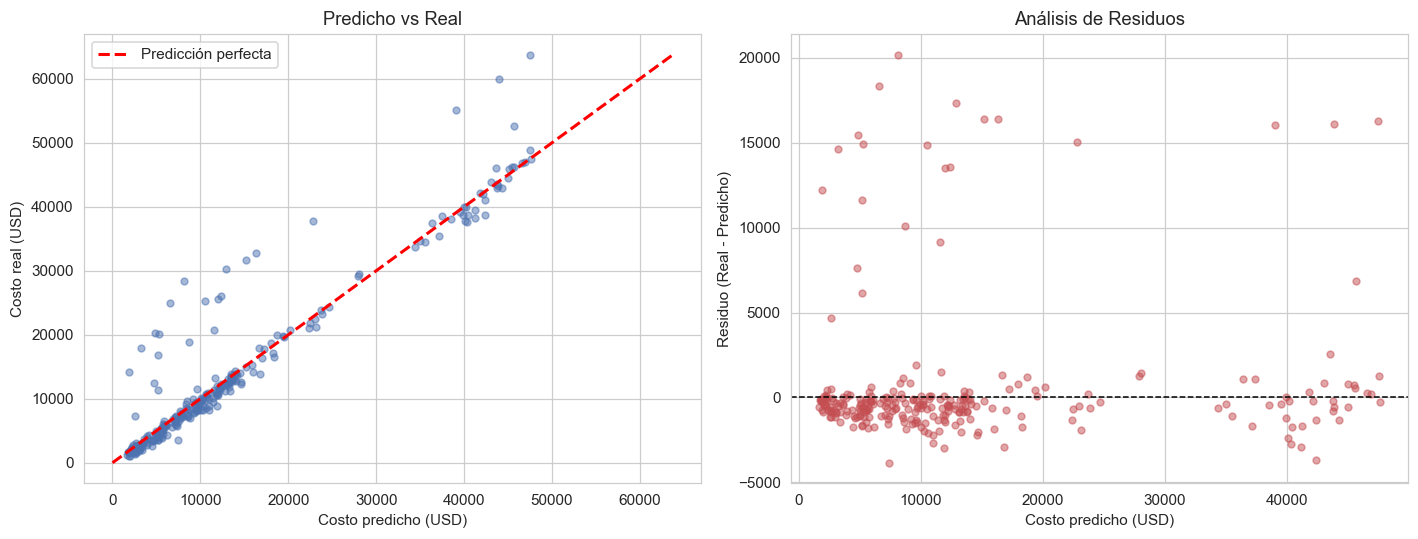


📌 Estadísticas de residuos (USD):
   Media:   $609   Mediana: $-460   Desv. estándar: $4,181

📌 10% más costoso del test (27 afiliados):
   Residuo promedio:  $1,845  (positivo = el modelo subestima)
   MAE en este grupo: $2,807  vs MAE global $1,895
   Subestimación relativa: 4.1% del costo medio del grupo
   ➜ Al presupuestar, conviene agregar un margen de reserva para los casos de mayor costo.


In [21]:
# ============================================================
# PASO 4.2 – Análisis de residuos
# ============================================================
# ¿Qué hace este código?
# Grafica la diferencia entre lo que el modelo predijo y lo que realmente
# costó (residuo = real - predicho). Residuo positivo = el modelo SUBESTIMA.
# Si hay un patrón (ej: siempre subestima los costos altos) → problema.
# ============================================================

residuos = y_test_dolares - y_pred_dolares

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred_dolares, y_test_dolares, alpha=0.5, s=20, color='#4C72B0')
axes[0].plot([0, y_test_dolares.max()], [0, y_test_dolares.max()],
             'r--', linewidth=2, label='Predicción perfecta')
axes[0].set_xlabel('Costo predicho (USD)')
axes[0].set_ylabel('Costo real (USD)')
axes[0].set_title('Predicho vs Real')
axes[0].legend()

axes[1].scatter(y_pred_dolares, residuos, alpha=0.5, s=20, color='#C44E52')
axes[1].axhline(y=0, color='k', linestyle='--', linewidth=1)
axes[1].set_xlabel('Costo predicho (USD)')
axes[1].set_ylabel('Residuo (Real - Predicho)')
axes[1].set_title('Análisis de Residuos')
plt.tight_layout()
plt.show()

print("\n📌 Estadísticas de residuos (USD):")
print(f"   Media:   ${residuos.mean():,.0f}   Mediana: ${np.median(residuos):,.0f}   Desv. estándar: ${residuos.std():,.0f}")

# Error en el 10% de afiliados más costosos
costo_alto = y_test_dolares > np.percentile(y_test_dolares, 90)
sub_prom = residuos[costo_alto].mean()
print(f"\n📌 10% más costoso del test ({costo_alto.sum()} afiliados):")
print(f"   Residuo promedio:  ${sub_prom:,.0f}  (positivo = el modelo subestima)")
print(f"   MAE en este grupo: ${np.abs(residuos[costo_alto]).mean():,.0f}  vs MAE global ${mae_final:,.0f}")
print(f"   Subestimación relativa: {sub_prom / y_test_dolares[costo_alto].mean() * 100:.1f}% del costo medio del grupo")
print("   ➜ Al presupuestar, conviene agregar un margen de reserva para los casos de mayor costo.")


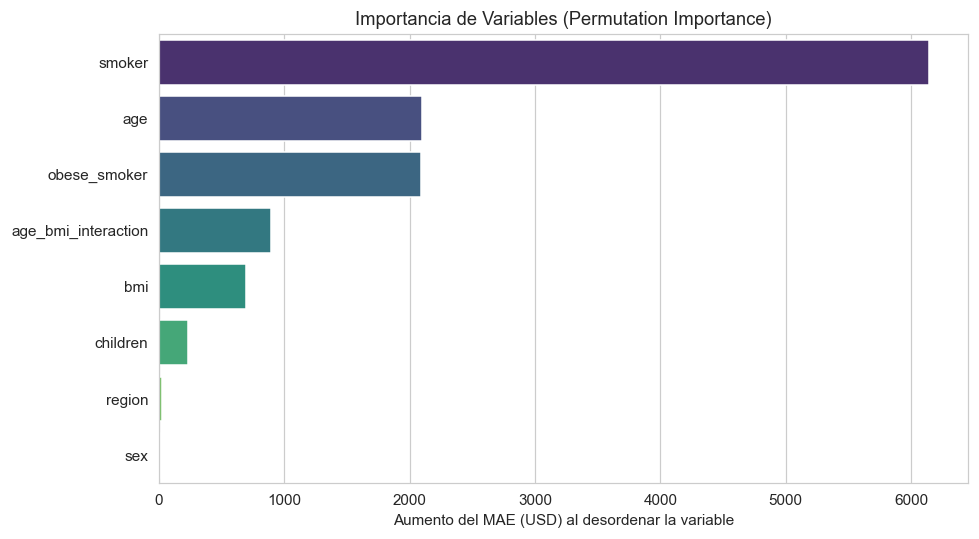


📌 Ranking de variables (aumento del MAE en USD al desordenarlas):
   smoker...................... $   6,146 ± 274
   age......................... $   2,101 ± 101
   obese_smoker................ $   2,094 ± 102
   age_bmi_interaction......... $     895 ± 29
   bmi......................... $     694 ± 68
   children.................... $     233 ± 31
   region...................... $      25 ± 14
   sex......................... $      12 ± 11


In [22]:
# ============================================================
# PASO 4.3 – Importancia de variables (Permutation Importance)
# ============================================================
# ¿Qué hace este código?
# Desordena al azar los valores de una variable y mide cuánto empeora el
# MAE (en USD). Si empeora mucho → la variable es importante.
# Nota: variables correlacionadas entre sí (age y age_bmi_interaction;
# smoker, bmi y obese_smoker) se reparten la importancia.
# ============================================================

from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    mejor_modelo, X_test, y_test,
    n_repeats=10, random_state=42, scoring=mae_dolares
)

feature_names = features_numericas + features_categoricas   # mismo orden que X
feat_imp = pd.DataFrame({
    'variable': feature_names,
    'aumento_MAE_usd': perm_importance.importances_mean,
    'desv': perm_importance.importances_std
}).sort_values('aumento_MAE_usd', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp, x='aumento_MAE_usd', y='variable', hue='variable',
            palette='viridis', legend=False, orient='h')
plt.title('Importancia de Variables (Permutation Importance)')
plt.xlabel('Aumento del MAE (USD) al desordenar la variable')
plt.ylabel('')
plt.tight_layout()
plt.show()

print("\n📌 Ranking de variables (aumento del MAE en USD al desordenarlas):")
for _, row in feat_imp.iterrows():
    print(f"   {row['variable']:.<28} ${row['aumento_MAE_usd']:>8,.0f} ± {row['desv']:,.0f}")


✅ Columnas transformadas: 10 | Nombres: 10
    ['age', 'bmi', 'children', 'obese_smoker', 'age_bmi_interaction', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


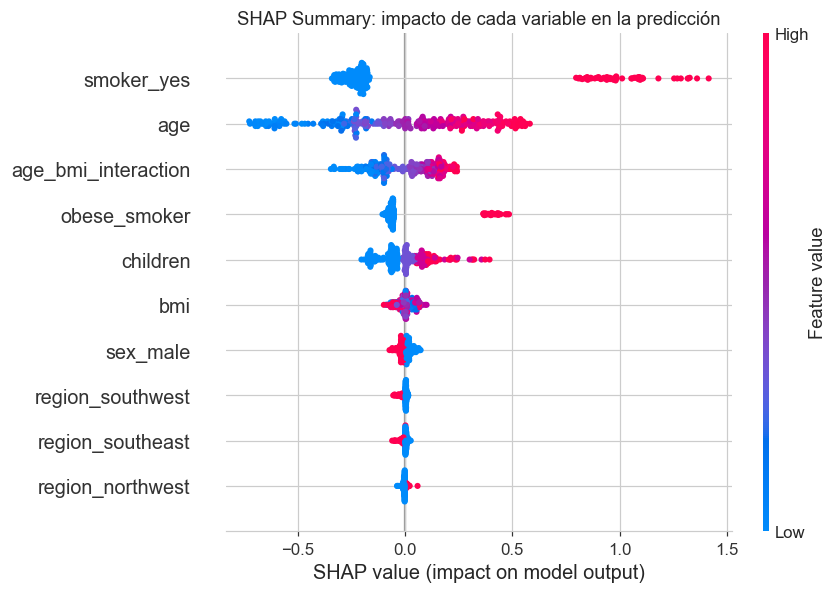


📌 Cómo leer el gráfico SHAP:
   • Puntos a la DERECHA → la variable AUMENTA el costo predicho; a la IZQUIERDA lo DISMINUYE
   • Color: rojo = valor alto de la variable, azul = valor bajo
   • Variables más arriba = más importantes


In [23]:
# ============================================================
# PASO 4.4 – Valores SHAP (explicabilidad del modelo)
# ============================================================
# ¿Qué hace este código?
# SHAP calcula cuánto aporta cada variable a cada predicción individual
# (en escala log del costo).
# - Summary plot: qué variables empujan el costo hacia arriba o abajo.
# Requiere: pip install shap
# ============================================================

import shap
from scipy import sparse

def a_denso(m):
    return np.asarray(m.toarray() if sparse.issparse(m) else m, dtype=float)

modelo_entrenado = mejor_modelo.named_steps['modelo']
prep_ajustado = mejor_modelo.named_steps['prep']
X_test_transformed = a_denso(prep_ajustado.transform(X_test))

# Nombres reales de las columnas transformadas (one-hot genera más columnas)
shap_feature_names = [n.split('__', 1)[1] for n in prep_ajustado.get_feature_names_out()]
print(f"✅ Columnas transformadas: {X_test_transformed.shape[1]} | Nombres: {len(shap_feature_names)}")
print("   ", shap_feature_names)

# TreeExplainer es exacto para árboles; si la versión instalada no soporta el
# modelo, se usa el explicador genérico de SHAP como alternativa.
try:
    explainer = shap.TreeExplainer(modelo_entrenado)
    shap_values = explainer.shap_values(X_test_transformed)
except Exception as e:
    print("TreeExplainer no disponible para este modelo; se usa shap.Explainer genérico:", type(e).__name__)
    X_train_transformed = a_denso(prep_ajustado.transform(X_train))
    explainer = shap.Explainer(modelo_entrenado.predict, X_train_transformed[:200])
    shap_values = explainer(X_test_transformed).values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=shap_feature_names, show=False)
plt.title('SHAP Summary: impacto de cada variable en la predicción')
plt.tight_layout()
plt.show()

print("\n📌 Cómo leer el gráfico SHAP:")
print("   • Puntos a la DERECHA → la variable AUMENTA el costo predicho; a la IZQUIERDA lo DISMINUYE")
print("   • Color: rojo = valor alto de la variable, azul = valor bajo")
print("   • Variables más arriba = más importantes")


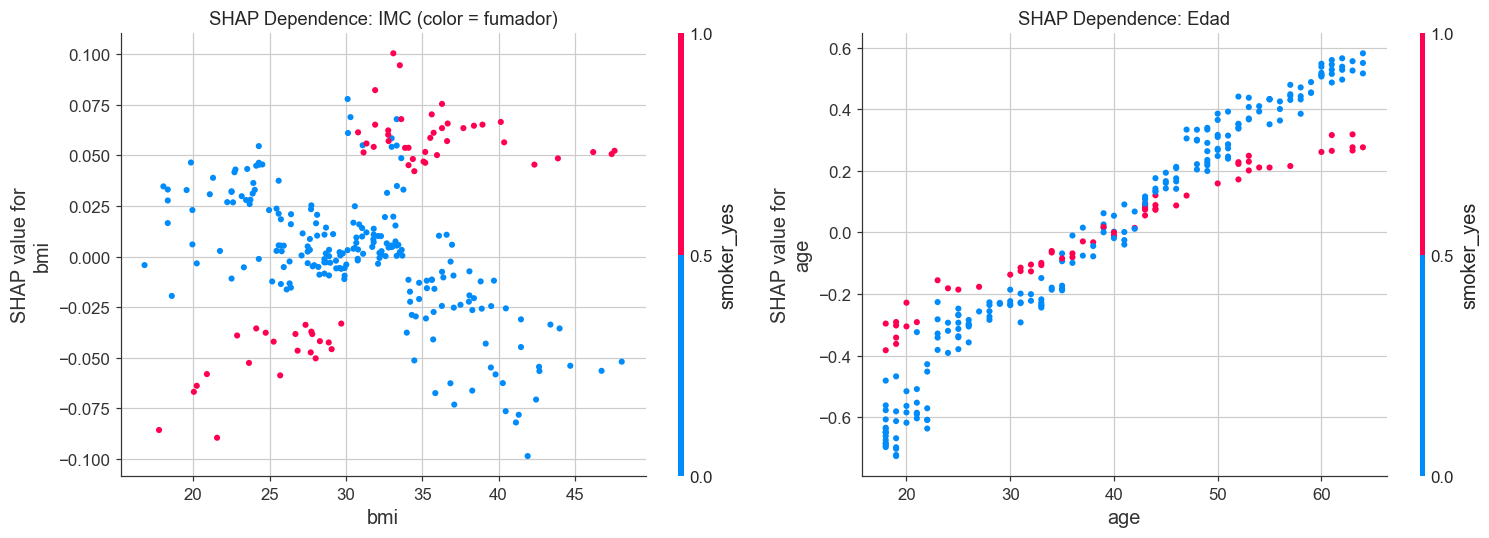


📌 Efecto SHAP promedio del IMC (escala log del costo):
   IMC ≥ 30, fumadores:    +0.060  (n=38)
   IMC ≥ 30, no fumadores: -0.009  (n=115)
   IMC < 30, fumadores:    -0.049  (n=22)
   IMC < 30, no fumadores: +0.012  (n=93)


In [24]:
# ============================================================
# PASO 4.5 – SHAP Dependence Plot para IMC y edad
# ============================================================
# ¿Qué hace este código?
# Muestra cómo cambia el efecto SHAP del IMC y de la edad, y cuantifica
# el efecto del IMC ≥ 30 en fumadores frente a no fumadores.
# ============================================================

i_bmi = shap_feature_names.index('bmi')
i_age = shap_feature_names.index('age')
i_smoker = shap_feature_names.index('smoker_yes')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
shap.dependence_plot(i_bmi, shap_values, X_test_transformed, interaction_index=i_smoker,
                     feature_names=shap_feature_names, ax=axes[0], show=False)
axes[0].set_title('SHAP Dependence: IMC (color = fumador)')
shap.dependence_plot(i_age, shap_values, X_test_transformed,
                     feature_names=shap_feature_names, ax=axes[1], show=False)
axes[1].set_title('SHAP Dependence: Edad')
plt.tight_layout()
plt.show()

# Cuantificación (en vez de afirmar sin medir)
fuma = X_test_transformed[:, i_smoker] == 1
obeso = X_test_transformed[:, i_bmi] >= 30
print("\n📌 Efecto SHAP promedio del IMC (escala log del costo):")
print(f"   IMC ≥ 30, fumadores:    {shap_values[fuma & obeso, i_bmi].mean():+.3f}  (n={int((fuma & obeso).sum())})")
print(f"   IMC ≥ 30, no fumadores: {shap_values[~fuma & obeso, i_bmi].mean():+.3f}  (n={int((~fuma & obeso).sum())})")
print(f"   IMC < 30, fumadores:    {shap_values[fuma & ~obeso, i_bmi].mean():+.3f}  (n={int((fuma & ~obeso).sum())})")
print(f"   IMC < 30, no fumadores: {shap_values[~fuma & ~obeso, i_bmi].mean():+.3f}  (n={int((~fuma & ~obeso).sum())})")


## Resumen del Entregable Funcional

**¿Qué entregamos?** Un modelo predictivo de costos médicos anuales (**Random Forest ajustado**) que:

1. **Funciona y cumple los criterios del informe (RF02):** en el conjunto de prueba (268 afiliados) logra **R² = 0,903 y MAE = \$1.895** (MAPE 16,7%). En validación cruzada 5-fold (control de estabilidad) obtiene R² = 0,858 ± 0,028 y MAE = \$2.011 ± 144. Ambos criterios (R² ≥ 0,85; MAE < \$2.100) se cumplen en test y en validación cruzada, aunque el margen del R² en validación cruzada es estrecho. Los baselines quedan muy por debajo (mediana: MAE \$8.352; regresión lineal: MAE \$4.111 y R² 0,45 en validación cruzada).
2. **Es explicable:** permutation importance y valores SHAP muestran por qué se estima un costo alto. El tabaquismo es la variable que más influye, seguida de la edad y de la combinación fumador con IMC ≥ 30.
3. **Responde al negocio:** el tabaquismo, sobre todo combinado con obesidad, es el principal factor de riesgo financiero.

**Limitación a considerar al presupuestar:** en el 10% de afiliados más costosos el modelo **subestima en promedio \$1.845** (≈ 4% de su costo medio) y su error es mayor (MAE \$2.807 contra \$1.895 global). Para reservas de presupuesto conviene agregar un margen para ese grupo.

**Decisiones técnicas justificadas:**

| Decisión | Justificación |
|----------|---------------|
| Transformación log1p(charges) | El costo es asimétrico (asimetría = 1,52); el log reduce el peso de la cola. Las métricas se reportan siempre en USD. |
| Random Forest seleccionado | Menor MAE en validación cruzada que Gradient Boosting (\$2.156 contra \$2.509 sin ajuste) y es más simple de explicar. Los árboles capturan interacciones no lineales (IMC × tabaquismo). |
| Validación cruzada 5-fold y test independiente | La validación cruzada evita depender de una sola partición; el 20% de prueba se usa una sola vez, después del ajuste. |
| Hiperparámetros ajustados solo con entrenamiento | Evita fuga de información hacia el conjunto de prueba. |
| Variable `obese_smoker` | La ablación muestra que mejora el MAE en \$168 (8%). |
| Variable `age_bmi_interaction` | La ablación no muestra mejora; se mantiene sin perjudicar y es candidata a eliminarse. |
| SHAP para interpretabilidad | El negocio necesita entender el "por qué", no solo el "cuánto". |


## 1.1 Análisis ético

### Identificación de sesgos en los datos

- **Sesgo socioeconómico indirecto:** IMC y tabaquismo correlacionan con factores socioeconómicos, estrés y acceso a educación preventiva. Un modelo que penalice estas variables puede castigar algorítmicamente a los sectores más vulnerables.
- **Sesgo de representatividad — a vigilar:** regiones y sexo tienen tamaños parecidos, pero el tabaquismo y el costo medio difieren entre grupos (ver evidencia). No se descarta; se audita por sexo, región y edad y se mantiene como control ante datos nuevos en producción.
- **Variables omitidas (*omitted variable bias*):** el dataset no incluye comorbilidades, medicamentos ni historia clínica; el modelo atribuye a IMC y edad efectos que pueden deberse a condiciones no observadas, inflando el riesgo aparente de ciertos perfiles.

### Impactos éticos potenciales del modelo

- **Discriminación y exclusión:** si el modelo se usa para fijar primas individuales, personas mayores, fumadoras o con alto IMC enfrentarían primas impagables, vulnerando el acceso equitativo a la salud. El caso pide estimar **presupuestos y prevención**, no tarificar personas.
- **Determinismo algorítmico:** el modelo evalúa el estado actual, no el esfuerzo del paciente (por ejemplo, alto IMC en tratamiento activo).
- **Opacidad:** un modelo sin explicabilidad impide que un afiliado entienda o apele un ajuste de su plan.

### Medidas para mitigar sesgos y riesgos éticos

1. **Auditoría de equidad periódica** (ejecutada a continuación como validación de la medida).
2. **Enfoque preventivo, no punitivo:** derivación temprana del segmento de riesgo a programas de cesación tabáquica y nutrición sin costo.
3. **Transparencia y explicabilidad:** todo ajuste de plan debe ser explicable (importancias de variables, SHAP) y con vía humana de apelación.
4. **Gobernanza de uso:** prohibir contractualmente el uso para primas individuales; restringirlo a presupuestos agregados.

### Validación de la mitigación N°1: auditoría de equidad

Se audita el **modelo final** (el mismo que se evaluó arriba, no un prototipo) sobre el conjunto de prueba, para verificar que las predicciones no cometen errores sistemáticamente mayores según sexo, región, edad o segmento de riesgo. Además de la brecha de MAE entre mujeres y hombres (umbral < 10%), se calcula una razón de calibración entre grupos (mediana de predicho/real de un grupo dividida por la del otro; umbral informe RNF07: entre 0,8 y 1,25). La razón de calibración es una adaptación al caso de regresión del *Disparate Impact Ratio* y debe confirmarse con el Comité de Ética.


In [25]:
from scipy.stats import mannwhitneyu

pred = np.expm1(mejor_modelo.predict(X_test))
real = y_test_real.values
print(f"Modelo auditado: {mejor_familia} ajustado | R² = {r2_score(real, pred):.3f} | "
      f"MAE = ${mean_absolute_error(real, pred):,.0f} | {len(X_test)} afiliados en prueba")

auditoria = pd.DataFrame({
    'sexo': X_test['sex'].values,
    'region': X_test['region'].values,
    'edad': pd.cut(X_test['age'].values, [17, 30, 45, 64], labels=['18-30', '31-45', '46-64']),
    'segmento': np.where(X_test['obese_smoker'].values == 1, 'Fumador IMC>=30', 'Resto'),
    'error_abs': np.abs(pred - real),
    'ratio': pred / real})
auditoria['error_rel_%'] = auditoria['error_abs'] / real * 100

def resumen_error(col):
    return auditoria.groupby(col, observed=True).agg(
        afiliados=('error_abs', 'size'), MAE=('error_abs', 'mean'),
        ratio_mediano=('ratio', 'median'),
        error_rel_mediano_pct=('error_rel_%', 'median')).round(3)

for col in ['sexo', 'segmento', 'region', 'edad']:
    display(resumen_error(col))

# Brecha de error entre mujeres y hombres y prueba de significancia
mae_sexo = auditoria.groupby('sexo')['error_abs'].mean()
brecha = abs(mae_sexo['female'] - mae_sexo['male']) / auditoria['error_abs'].mean() * 100
p = mannwhitneyu(auditoria.loc[auditoria['sexo'] == 'female', 'error_abs'],
                 auditoria.loc[auditoria['sexo'] == 'male', 'error_abs']).pvalue
print(f"Brecha MAE entre mujeres y hombres: {brecha:.1f}% del MAE total | Mann-Whitney p = {p:.3f}")

# Razón de calibración (adaptación del Disparate Impact Ratio)
r_sexo = auditoria.groupby('sexo')['ratio'].median()
dir_sexo = r_sexo['female'] / r_sexo['male']
r_reg = auditoria.groupby('region')['ratio'].median()
dir_reg = r_reg.min() / r_reg.max()
r_seg = auditoria.groupby('segmento')['ratio'].median()
dir_seg = r_seg.min() / r_seg.max()
print(f"Razón de calibración mujeres/hombres: {dir_sexo:.2f} | entre regiones (mín/máx): {dir_reg:.2f} | "
      f"entre segmentos (mín/máx): {dir_seg:.2f}  (rango aceptado 0,80–1,25)")

seg_riesgo = auditoria['segmento'] != 'Resto'
print(f"Fumadores IMC>=30: {seg_riesgo.mean() * 100:.1f}% de la muestra de prueba y "
      f"{auditoria.loc[seg_riesgo, 'error_abs'].sum() / auditoria['error_abs'].sum() * 100:.1f}% del error absoluto total")


Modelo auditado: Random Forest ajustado | R² = 0.903 | MAE = $1,895 | 268 afiliados en prueba


,afiliados,MAE,ratio_mediano,error_rel_mediano_pct
sexo,,,,
female,143,1817.637,1.039,6.570
male,125,1982.917,1.066,9.539


,afiliados,MAE,ratio_mediano,error_rel_mediano_pct
segmento,,,,
Fumador IMC>=30,38,2405.341,1.006,2.271
Resto,230,1810.364,1.065,9.826


,afiliados,MAE,ratio_mediano,error_rel_mediano_pct
region,,,,
northeast,71,2482.952,1.014,5.544
northwest,60,1852.935,1.033,5.828
southeast,77,1677.428,1.075,11.864
southwest,60,1519.317,1.071,8.099


,afiliados,MAE,ratio_mediano,error_rel_mediano_pct
edad,,,,
18-30,87,1548.006,1.126,18.505
31-45,79,2139.258,1.039,6.301
46-64,102,2001.066,1.035,5.539


Brecha MAE entre mujeres y hombres: 8.7% del MAE total | Mann-Whitney p = 0.046
Razón de calibración mujeres/hombres: 0.97 | entre regiones (mín/máx): 0.94 | entre segmentos (mín/máx): 0.94  (rango aceptado 0,80–1,25)
Fumadores IMC>=30: 14.2% de la muestra de prueba y 18.0% del error absoluto total


**Resultado de la auditoría (modelo final, conjunto de prueba de 268 afiliados):**

- **Sexo:** el MAE es \$1.818 en mujeres y \$1.983 en hombres. La brecha es de **8,7%** del MAE total: está bajo el umbral de 10%, pero con poco margen, y la diferencia es marginalmente significativa (Mann-Whitney, p = 0,046). La razón de calibración mujeres/hombres es 0,97, dentro del rango 0,80–1,25. **Cumple los umbrales, pero queda como punto a vigilar.**
- **Segmento de riesgo:** el error en dólares es mayor en fumadores con IMC ≥ 30 (≈ \$2.405 contra ≈ \$1.810), pero sigue la escala de sus costos: su error relativo mediano (≈ 2%) es mucho menor que el del resto (≈ 10%). Son el 14,2% de la muestra y aportan el 18,0% del error total, así que el error **no se concentra** en ellos.
- **Región:** el MAE va de ≈ \$1.519 (southwest) a ≈ \$2.483 (northeast), una diferencia de más del 60%. La razón de calibración entre regiones es 0,94 (dentro del rango). Con solo 60 a 77 casos por región no se puede concluir sesgo, pero **tampoco equidad regional**: es el punto a vigilar primero.
- **Edad:** el MAE es menor en 18–30 años (≈ \$1.548) que en 31–45 (≈ \$2.139) y 46–64 (≈ \$2.001); en 18–30 el modelo sobreestima más (error relativo mediano ≈ 18%).

Esta auditoría es de una sola partición. Debe repetirse en cada reentrenamiento y con más de una partición, porque la equidad es una propiedad del modelo en uso, no un chequeo único.


## 1.2 Evaluación financiera

Costos mensuales estimados (USD) de las dos alternativas para poner la solución en producción, cubriendo los cuatro rubros exigidos por la pauta: infraestructura cloud, licencias de software, recursos humanos y agentes o servicios automáticos.

- **Alternativa 1 — Cloud administrado (Enterprise):** servicios 100% administrados (AWS SageMaker), licencias privativas (Power BI/Tableau) y automatización nativa. Menor tiempo de configuración, altos costos recurrentes y *vendor lock-in*.
- **Alternativa 2 — Open Source + Contenedores:** modelos contenerizados (Docker) en instancias de cómputo eficientes, CI/CD con GitHub Actions y visualización open source (Metabase). Mayor esfuerzo de configuración, costos optimizados y control granular de seguridad.

,Categoría,Alternativa 1 (Enterprise),Alternativa 2 (Open Source)
0,Infraestructura Cloud,800,150
1,Licencias de Software,300,0
2,Recursos Humanos (proporcional),3500,3800
3,Agentes / Automatización,250,50
4,TOTAL MENSUAL,4850,4000


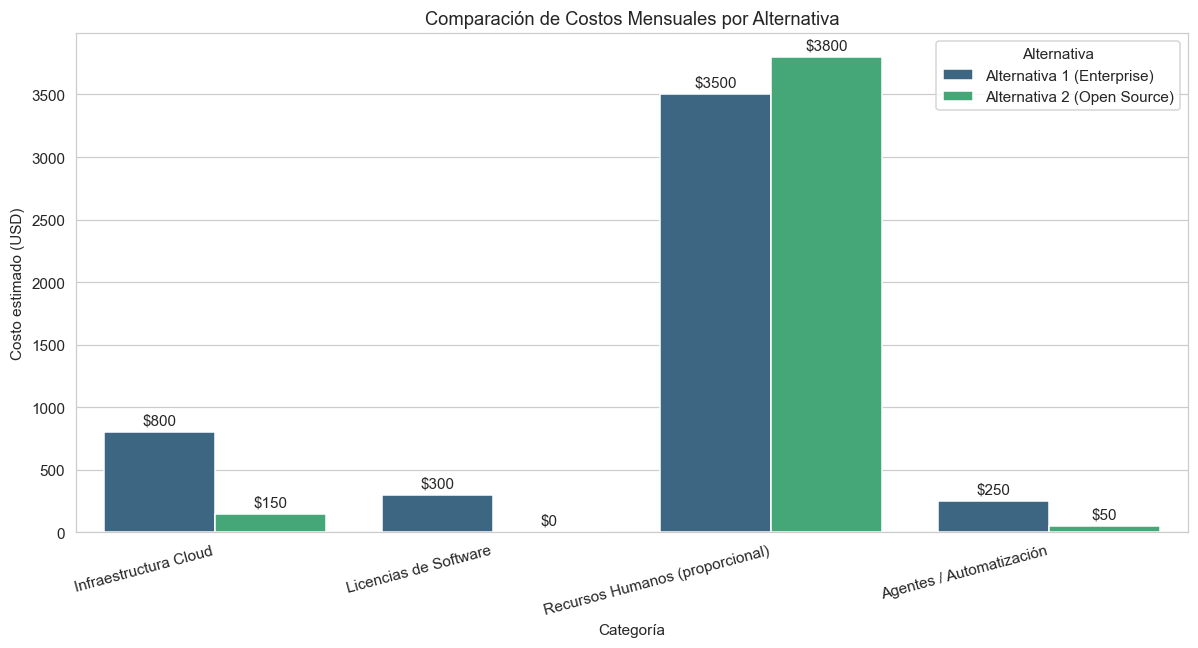

In [26]:
datos_costos = {
    'Categoría': ['Infraestructura Cloud', 'Licencias de Software',
                  'Recursos Humanos (proporcional)', 'Agentes / Automatización'],
    'Alternativa 1 (Enterprise)': [800, 300, 3500, 250],
    'Alternativa 2 (Open Source)': [150, 0, 3800, 50]
}
df_costos = pd.DataFrame(datos_costos)
df_costos.loc[len(df_costos)] = ['TOTAL MENSUAL'] + list(
    df_costos[['Alternativa 1 (Enterprise)', 'Alternativa 2 (Open Source)']].sum())
display(df_costos)

df_grafico = df_costos.iloc[:-1].melt(id_vars='Categoría', var_name='Alternativa', value_name='Costo (USD)')
plt.figure(figsize=(11, 6))
grafico = sns.barplot(data=df_grafico, x='Categoría', y='Costo (USD)', hue='Alternativa', palette='viridis')
for container in grafico.containers:
    grafico.bar_label(container, fmt='$%.0f', padding=3)
plt.title('Comparación de Costos Mensuales por Alternativa')
plt.xticks(rotation=15, ha='right')
plt.ylabel('Costo estimado (USD)')
plt.tight_layout(); plt.show()

**Justificación de la alternativa seleccionada — Alternativa 2 (Open Source + Contenedores, \$4.000/mes):**

Ahorro de **\$850/mes (\$10.200/año, 17,5% menos que la Alternativa 1)**, eliminando el *vendor lock-in* de licencias y manteniendo control total sobre la seguridad de los datos de salud (red privada, contenedores aislados). El sobre-costo de RR.HH. (+\$300/mes por operar Docker y pipelines) queda como conocimiento interno acumulable, mientras que el costo de la Alternativa 1 se paga mes a mes sin generar activo propio. Técnicamente, el prototipo (Random Forest) entrena en segundos sobre 1.337 registros en CPU: **no se justifica pagar infraestructura enterprise** para esta carga de trabajo.

## 1.3 Análisis de riesgos

Matriz de riesgos en las dimensiones técnica, legal, financiera y ética, con niveles de probabilidad e impacto (escala 1–5) y estrategia de mitigación por riesgo.

In [27]:
datos_riesgos = {
    'ID': ['R1', 'R2', 'R3', 'R4'],
    'Tipo': ['Ético', 'Técnico', 'Legal', 'Financiero'],
    'Descripción del Riesgo': [
        'Modelo predictivo sesgado contra pacientes fumadores o con alto IMC.',
        'Caída del servidor o latencia en consultas a la base de datos.',
        'Incumplimiento de normativas de privacidad de datos médicos (Ley 19.628 / GDPR).',
        'Sobrecostos en infraestructura por mal dimensionamiento.'
    ],
    'Probabilidad (1-5)': [4, 3, 2, 3],
    'Impacto (1-5)': [5, 4, 5, 3],
    'Estrategia de Mitigación': [
        'Auditorías de equidad periódicas (error por sexo/edad/región) y revisión humana antes de decisiones.',
        'Contenedores escalables, balanceadores de carga y plan de respaldo y recuperación.',
        'Anonimización de datos (enmascarar RUT/nombres) antes del análisis y control de accesos.',
        'Alertas de presupuesto (billing alarms) y monitoreo continuo de uso de recursos.'
    ]
}
df_riesgos = pd.DataFrame(datos_riesgos)
df_riesgos['Criticidad'] = df_riesgos['Probabilidad (1-5)'] * df_riesgos['Impacto (1-5)']
df_riesgos = df_riesgos.sort_values('Criticidad', ascending=False).reset_index(drop=True)

def resaltar_criticidad(val):
    if val >= 15: color = '#f83400'
    elif val >= 10: color = '#ffb217'
    else: color = '#308446'
    return 'background-color: ' + color + '; color: white'

display(df_riesgos.style.map(resaltar_criticidad, subset=['Criticidad']))

,ID,Tipo,Descripción del Riesgo,Probabilidad (1-5),Impacto (1-5),Estrategia de Mitigación,Criticidad
0,R1,Ético,Modelo predictivo sesgado contra pacientes fumadores o con alto IMC.,4,5,Auditorías de equidad periódicas (error por sexo/edad/región) y revisión humana antes de decisiones.,20
1,R2,Técnico,Caída del servidor o latencia en consultas a la base de datos.,3,4,"Contenedores escalables, balanceadores de carga y plan de respaldo y recuperación.",12
2,R3,Legal,Incumplimiento de normativas de privacidad de datos médicos (Ley 19.628 / GDPR).,2,5,Anonimización de datos (enmascarar RUT/nombres) antes del análisis y control de accesos.,10
3,R4,Financiero,Sobrecostos en infraestructura por mal dimensionamiento.,3,3,Alertas de presupuesto (billing alarms) y monitoreo continuo de uso de recursos.,9


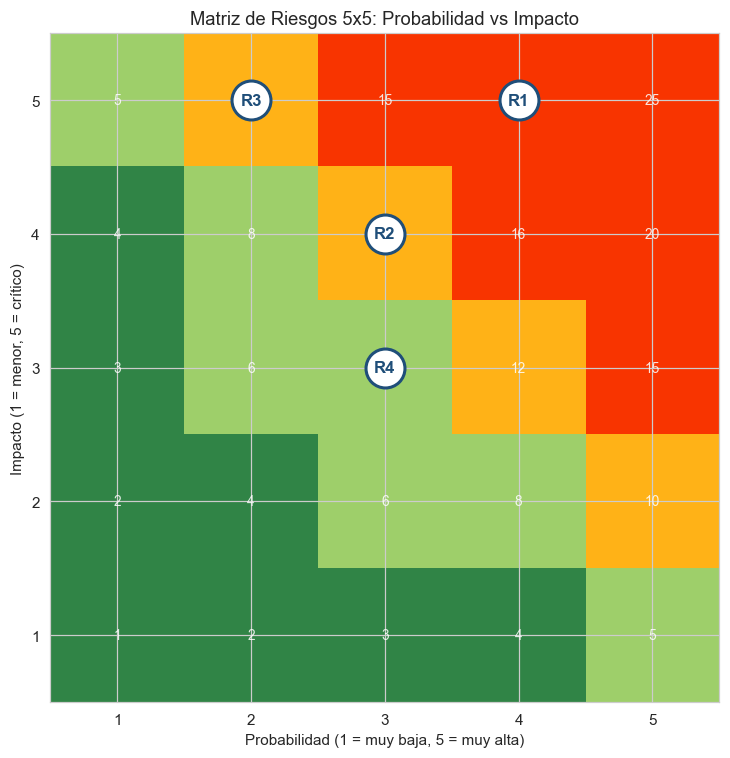

In [28]:
from matplotlib.colors import ListedColormap, BoundaryNorm

fig, ax = plt.subplots(figsize=(9, 7))
score = np.array([[(i + 1) * (j + 1) for j in range(5)] for i in range(5)])
cmap = ListedColormap(['#308446', '#9ecf6a', '#ffb217', '#f83400'])
norm = BoundaryNorm([0, 5, 10, 15, 25], cmap.N)
ax.imshow(score, cmap=cmap, norm=norm, origin='lower', extent=[0.5, 5.5, 0.5, 5.5])
for i in range(5):
    for j in range(5):
        ax.text(j + 1, i + 1, (i + 1) * (j + 1), ha='center', va='center',
                color='white', fontsize=9, alpha=0.85)
for _, r in df_riesgos.iterrows():
    ax.scatter(r['Probabilidad (1-5)'], r['Impacto (1-5)'], s=650,
               c='white', edgecolors='#1f4e79', linewidths=2, zorder=3)
    ax.text(r['Probabilidad (1-5)'], r['Impacto (1-5)'], r['ID'],
            ha='center', va='center', fontsize=11, fontweight='bold', zorder=4, color='#1f4e79')
ax.set_xticks(range(1, 6)); ax.set_yticks(range(1, 6))
ax.set_xlabel('Probabilidad (1 = muy baja, 5 = muy alta)')
ax.set_ylabel('Impacto (1 = menor, 5 = crítico)')
ax.set_title('Matriz de Riesgos 5x5: Probabilidad vs Impacto')
plt.tight_layout(); plt.show()

**Análisis de la matriz:**

- **R1 (Ético, criticidad 20):** riesgo dominante. Un modelo sesgado daña a los pacientes y expone a la aseguradora a demandas y daño reputacional. Mitigación prioritaria: auditorías de equidad integradas al monitoreo (validada en la sección 1.1).
- **R2 (Técnico, criticidad 12):** la disponibilidad se mitiga con la arquitectura de contenedores de la Alternativa 2, escalable horizontalmente.
- **R3 (Legal, criticidad 10):** probabilidad baja pero impacto crítico; la anonimización rigurosa previa al análisis es obligatoria.
- **R4 (Financiero, criticidad 9):** controlado con billing alarms; el ahorro de la Alternativa 2 (17,5%) genera margen adicional.

## Conclusión y recomendación final

1. **Técnica:** el Random Forest ajustado cumple los criterios de aceptación del informe (R² = 0,903 y MAE = \$1.895 en test; R² = 0,858 y MAE = \$2.011 en validación cruzada). Limitación: subestima en promedio \$1.845 al 10% más costoso, por lo que se recomienda un margen de reserva para ese grupo.
2. **Ética:** el proyecto es viable solo si el modelo se usa para **presupuestos agregados y prevención** (derivación del segmento fumador-obeso a programas de cesación tabáquica y nutrición), nunca para primas individuales. La auditoría sobre el modelo final cumple los umbrales (brecha por sexo 8,7%, razones de calibración entre 0,94 y 0,97), pero la brecha por sexo está cerca del límite y el error varía por región: ambos quedan como puntos de vigilancia permanente.
3. **Financiera:** se recomienda la **Alternativa 2 (Open Source + Contenedores, \$4.000/mes)**, con un ahorro del 17,5% frente a la alternativa enterprise y sin *vendor lock-in*.
4. **Riesgos:** el riesgo dominante es ético (sesgo algorítmico, criticidad 20); sus mitigaciones — auditorías de equidad periódicas, revisión humana y gobernanza de uso — son condiciones de pase a producción.

**Recomendación final:** el proyecto es **factible ética, financiera y técnicamente** bajo la Alternativa 2, con monitoreo continuo de equidad (MLOps) y uso restringido a estimación de presupuestos y programas preventivos.


## Referencias

- Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and machine learning: Limitations and opportunities*. MIT Press.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Choi, M. (2018). *Medical cost personal datasets* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/mirichoi0218/insurance
- Ministerio Secretaría General de la Presidencia, Gobierno de Chile. (1999). *Ley N.º 19.628 sobre protección de la vida privada*. Biblioteca del Congreso Nacional de Chile. https://www.bcn.cl/leyes/chile
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

## Guardado del entregable

In [29]:
# ============================================================
# PASO 5 – Guardar el modelo y las métricas (entregable funcional)
# ============================================================
# ¿Qué hace este código?
# Guarda el pipeline entrenado y las métricas finales para que otras
# personas puedan reproducir y reutilizar el modelo sin reentrenar.
# Archivos: modelo_costos_medicos.joblib y metricas_modelo.json
# ============================================================

import json, joblib

joblib.dump(mejor_modelo, 'modelo_costos_medicos.joblib')
metricas = {
    'modelo': mejor_familia,
    'hiperparametros': {k.replace('modelo__', ''): (None if v is None else (float(v) if isinstance(v, float) else v))
                        for k, v in search.best_params_.items()},
    'test': {'MAE_usd': round(float(mae_final), 1), 'MAPE_pct': round(float(mape_final), 2), 'R2': round(float(r2_final), 4)},
    'cv_5fold': {k: round(float(v), 4) for k, v in cv_final.items()},
    'cumple_RF02_en_test': bool(r2_final >= UMBRAL_R2 and mae_final < UMBRAL_MAE),
}
with open('metricas_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)
print(json.dumps(metricas, ensure_ascii=False, indent=2))

# Verificación: el modelo guardado reproduce las predicciones
modelo_cargado = joblib.load('modelo_costos_medicos.joblib')
assert np.allclose(modelo_cargado.predict(X_test), mejor_modelo.predict(X_test))
print("\n✅ Modelo guardado y verificado (las predicciones coinciden).")


{
  "modelo": "Random Forest",
  "hiperparametros": {
    "n_estimators": 300,
    "min_samples_leaf": 3,
    "max_features": 0.5,
    "max_depth": 8
  },
  "test": {
    "MAE_usd": 1894.7,
    "MAPE_pct": 16.65,
    "R2": 0.9032
  },
  "cv_5fold": {
    "MAE": 2011.4183,
    "MAE_std": 143.5391,
    "R2": 0.8575,
    "R2_std": 0.0278
  },
  "cumple_RF02_en_test": true
}

✅ Modelo guardado y verificado (las predicciones coinciden).


In [ ]:
''''
Es para que puedas leer el modelo guardado y las métricas de una forma mas visual, como se estructura el modelo y las métricas, sin necesidad de reentrenar el modelo. 
Esto es útil para auditorías, revisiones o para integrarlo en un sistema de producción sin tener que ejecutar todo el pipeline de entrenamiento nuevamente.
'''
import joblib

# Ruta a tu archivo .joblib
ruta_archivo = "modelo_costos_medicos.joblib"

# Leer o cargar el objeto
objeto_cargado = joblib.load(ruta_archivo)
display(objeto_cargado)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['age','bmi','children',...,'sex','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the out